In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


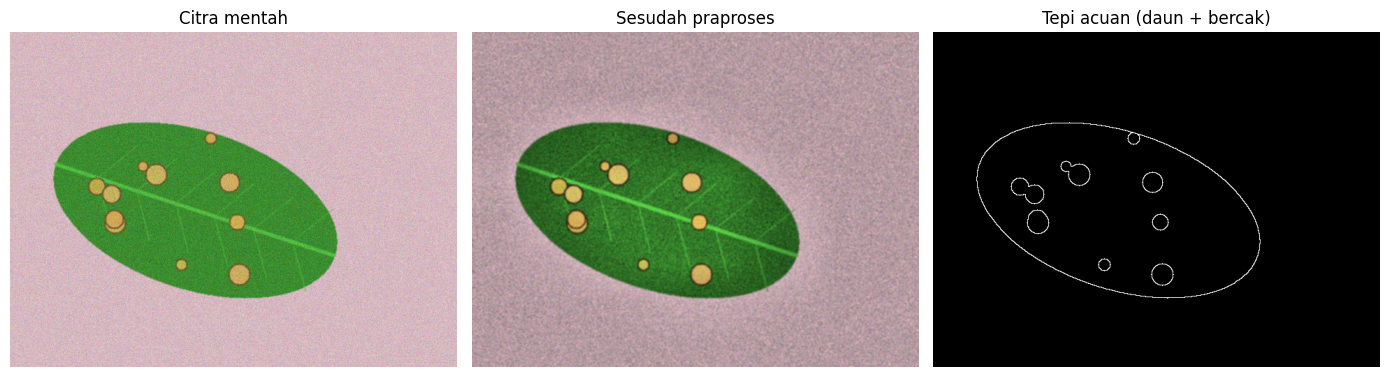

In [ ]:
# Kode 1.1 Persiapan: modul, data, praproses, dan tepi acuan
import sys, json
sys.path.append("/content/drive/MyDrive/simuteh-2330511092/src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
# Memuat parameter hasil Evaluasi P1-P4
PARAM = json.load(open("/content/drive/MyDrive/simuteh-2330511092/hasil/param_praproses.json"))
label = pd.read_csv("/content/drive/MyDrive/simuteh-2330511092/data/sintetis/label.csv")

def muat(nama):
    img = baca(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/citra/{nama}")
    md = cv2.imread(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

img, md, mb = muat("teh_041.png")
pra = praproses(img, PARAM)

acuan = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
tampil([img, pra, acuan], ["Citra mentah", "Sesudah praproses", "Tepi acuan (daun + bercak)"])

selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 509.2


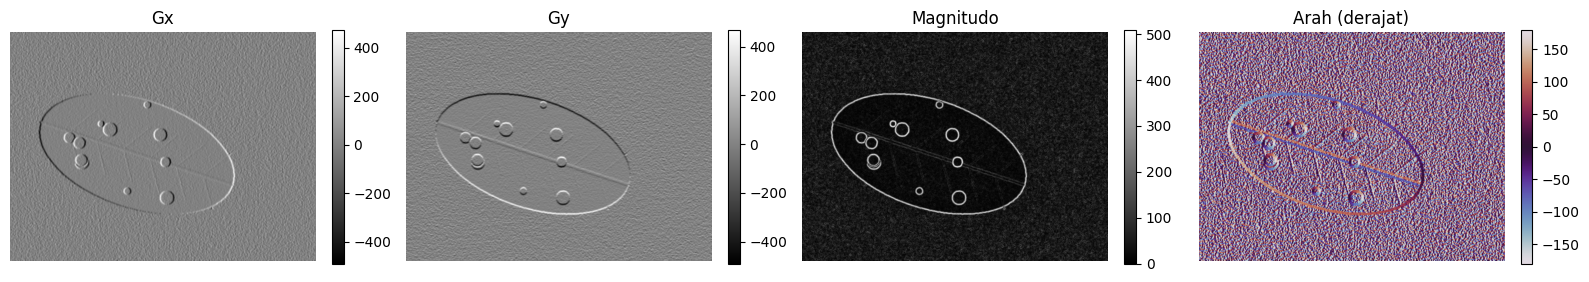

In [ ]:
# Kode 1.2 Gradien Sobel manual: Gx, Gy, magnitudo, dan arah
g = pra[:, :, 2].astype(np.float32)       # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T

gx = cv2.filter2D(g, cv2.CV_32F, kx)      # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky)      # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))

# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))

plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah, "Arah (derajat)")]):
    plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else "gray")
    plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)
plt.tight_layout()
plt.show()

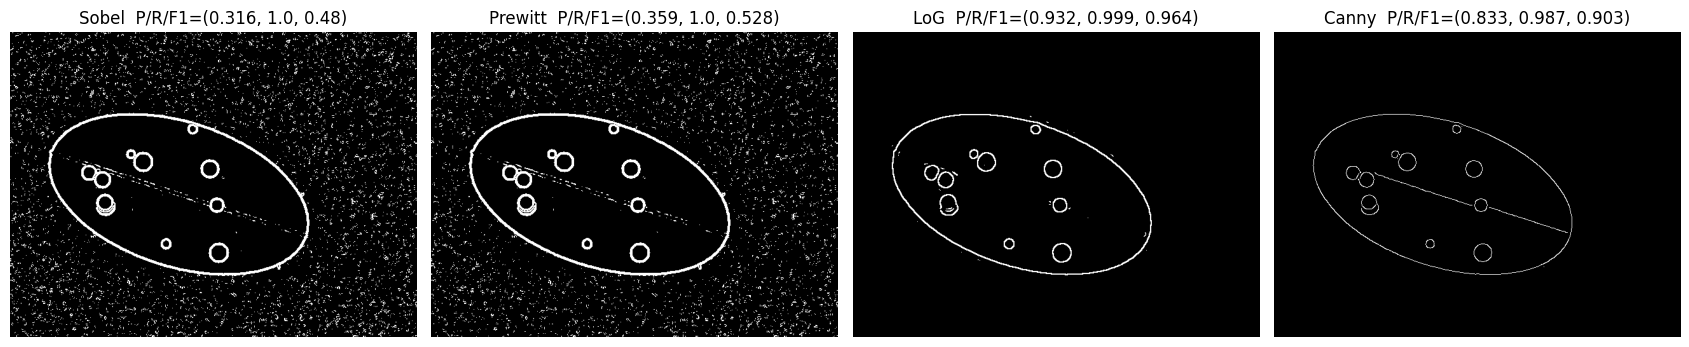

In [ ]:
# Kode 1.3 Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya
def tepi_sobel(g, T=100):
    g = g.astype(np.float32)
    m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    return ((m > T) * 255).astype(np.uint8)

def tepi_prewitt(g, T=75):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
    g = g.astype(np.float32)
    m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
    return ((m > T) * 255).astype(np.uint8)

def tepi_log(g, sigma=3.0, frac=0.2):
    """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
    L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma), cv2.CV_32F)
    mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
    return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) * 255).astype(np.uint8)

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log, "Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm}  P/R/F1={skor_tepi(e, acuan)}" for nm, e in hasil.items()],
       ukuran=(17, 3.6))

In [ ]:
# Kode 1.4 Tabel presisi, recall, dan F1 tepi
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
        for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R", im[:, :, 2])]:
            for nm, f in metode.items():
                p, r, f1 = skor_tepi(f(g), ac)
                baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])

tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal", "metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R", "F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("/content/drive/MyDrive/simuteh-2330511092/hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.744  0.748  0.744
                LoG      0.602  0.996  0.741
                Prewitt  0.779  0.956  0.846
                Sobel    0.744  0.964  0.826
          R     Canny    0.982  0.980  0.980
                LoG      0.889  0.997  0.931
                Prewitt  0.589  0.995  0.681
                Sobel    0.540  0.995  0.633
praproses Gray  Canny    0.686  0.940  0.786
                LoG      0.528  0.996  0.678
                Prewitt  0.640  0.996  0.773
                Sobel    0.621  0.996  0.758
          R     Canny    0.965  0.990  0.976
                LoG      0.819  0.997  0.884
                Prewitt  0.647  0.997  0.762
                Sobel    0.617  0.997  0.735


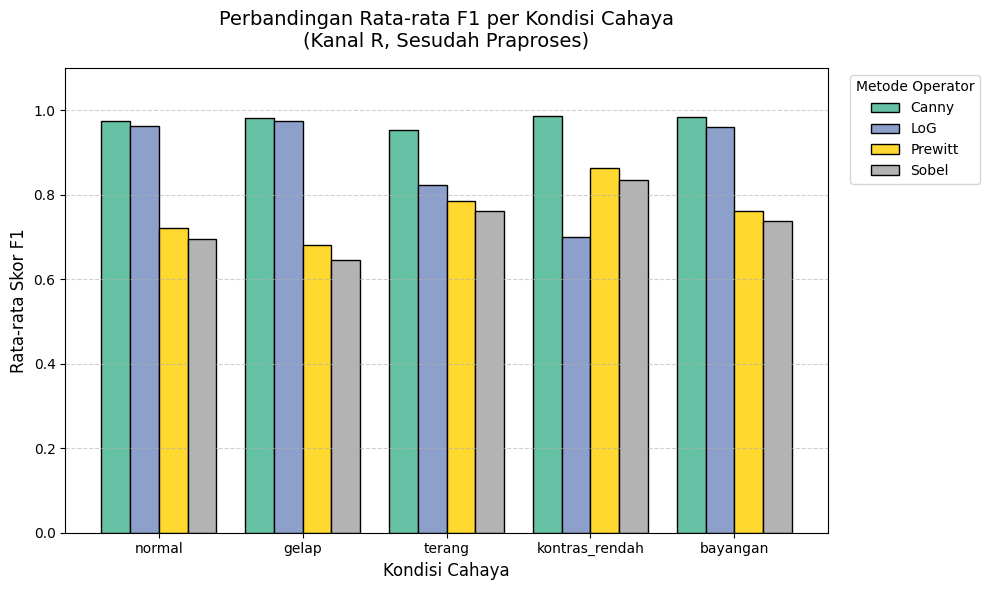

Grafik berhasil disimpan di: /content/drive/MyDrive/simuteh-2330511092/hasil/p5_f1_kondisi.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca data dari CSV yang baru saja dihasilkan di Langkah 1.4
tabel_tepi = pd.read_csv("/content/drive/MyDrive/simuteh-2330511092/hasil/p5_tabel_tepi.csv")

# 2. Saring data: hanya ambil sumber='praproses' dan kanal='R'
df_filter = tabel_tepi[(tabel_tepi['sumber'] == 'praproses') & (tabel_tepi['kanal'] == 'R')]

# 3. Ubah bentuk tabel menggunakan pivot_table dengan rata-rata (aggfunc='mean') agar mengatasi duplikasi data gambar
df_pivot = df_filter.pivot_table(index='kondisi', columns='metode', values='F1', aggfunc='mean')

# Urutkan kondisi pencahayaan agar rapi
urutan_kondisi = ['normal', 'gelap', 'terang', 'kontras_rendah', 'bayangan']
df_pivot = df_pivot.reindex(urutan_kondisi)

# 4. Buat grafik batang
plt.figure(figsize=(10, 6))
df_pivot.plot(kind='bar', ax=plt.gca(), width=0.8, colormap='Set2', edgecolor='black')

plt.title('Perbandingan Rata-rata F1 per Kondisi Cahaya\n(Kanal R, Sesudah Praproses)', fontsize=14, pad=15)
plt.xlabel('Kondisi Cahaya', fontsize=12)
plt.ylabel('Rata-rata Skor F1', fontsize=12)
plt.ylim(0, 1.1)  # Batas Y dari 0 hingga 1.1 agar ada ruang untuk legenda
plt.xticks(rotation=0)
plt.legend(title='Metode Operator', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()

# 5. Simpan grafik sesuai instruksi
path_simpan = "/content/drive/MyDrive/simuteh-2330511092/hasil/p5_f1_kondisi.png"
plt.savefig(path_simpan, dpi=300, bbox_inches='tight')
plt.show()

print(f"Grafik berhasil disimpan di: {path_simpan}")

In [11]:
%cd /content/drive/MyDrive/simuteh-2330511092

/content/drive/MyDrive/simuteh-2330511092


In [12]:
!git config --global user.email "gentaaditya18@gmail.com"
!git config --global user.name "Adityagenta"

In [13]:
!git commit -m "Menambahkan modul Pertemuan 5 (P5_tepi): evaluasi operator deteksi tepi, grafik F1"

On branch main
Your branch and 'origin/main' have diverged,
and have 2 and 1 different commits each, respectively.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   notebook/P5_tepi.ipynb

no changes added to commit (use "git add" and/or "git commit -a")


In [14]:
!git push origin main

To https://github.com/Adityagenta/simuteh-2330511092.git
 ! [rejected]        main -> main (non-fast-forward)
error: failed to push some refs to 'https://github.com/Adityagenta/simuteh-2330511092.git'
hint: Updates were rejected because the tip of your current branch is behind
hint: its remote counterpart. If you want to integrate the remote changes,
hint: use 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.
